# Pràctica Bloc III: Aerolínies i Satisfacció

* Assignatura: Aprenentatge Automàtic
* Integrants: Joan Gelabert – Xavier Estades
* Data: Gener 2026

## 1. Introducció

En aquesta pràctica s’apliquen diferents models d’aprenentatge automàtic amb l’objectiu de predir la satisfacció dels passatgers d’una aerolínia a partir d’informació demogràfica, característiques del vol i valoracions de diferents serveis.

L’objectiu principal no és únicament obtenir el millor rendiment, sinó analitzar i comparar de manera crítica el comportament dels diferents models, justificant totes les decisions preses al llarg del procés.
## Objectiu de la pràctica
Analitzar i comparar diferents models d’aprenentatge automàtic (Perceptró, Regressió Logística, SVM, Arbres de Decisió i Random Forest) per predir la satisfacció dels passatgers d’una aerolínia, utilitzant un conjunt de dades reals, aplicant preprocessament, EDA, ajust d’hiperparàmetres i mètriques d’avaluació adequades.


## 2. Càrrega inicial de les dades

En aquesta secció carregam el dataset test.csv, que conté:

- Dades demogràfiques (edat, gènere, tipus de client…)

- Informació del vol (classe, distància, tipus de viatge)

- Valoracions de serveis (wifi, menjar, seients, entreteniment, etc.)

- Variable objectiu: satisfaction (Satisfied / Neutral or Dissatisfied)



In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.cluster import KMeans

df = pd.read_csv("test.csv")
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied


## 4.Preprocessament

Aquest és un dels blocs més crítics del treball.

Tenim dos tipus de variables:

- Numèriques → edat, distància, puntuacions…

- Categòriques → classe, tipus de client, gènere…

I les tractam de forma diferent:

In [40]:
df = df.drop(columns=[c for c in ["Unnamed: 0", "id"] if c in df.columns])
target_col = "satisfaction"
X = df.drop(columns=[target_col])
y = (df[target_col] == "satisfied").astype(int)

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


Imputam amb la mediana → robust davant valors extrems.

Normalitzam → important per a models com SVM, logística i Perceptró.

In [41]:

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


Imputació per valor més freqüent.

Passam categories a columnes binàries.

In [42]:

preprocess = ColumnTransformer([
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

Tot això es combina amb ColumnTransformer perquè cada tipus de variable es tracti correctament dins un únic pipeline.

Això evita fuites d’informació i garanteix un entrenament net.

## 5. EDA amb KMeans

L’objectiu no és predir, sinó entendre patrons de clients:

- Agrupar passatgers segons el seu perfil i valoracions.
    
### Objectiu del clustering
L'objectiu d'aquest bloc és entendre patrons de clients sense utilitzar la variable objectiu directament.

Fem KMeans sobre les variables transformades (numèriques normalitzades i categòriques one-hot) per:
- Detectar perfils de passatgers amb experiències similars.
- Identificar grups potencialment associats a satisfacció/insatisfacció.
- Generar hipòtesis interpretables abans de modelitzar.

**Important:** el clustering s'entrena només amb X_train per evitar fuites d'informació.

Després analitzam la mitjana de cada clúster:

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train_trans = preprocess.fit_transform(X_train)

kmeans = KMeans(n_clusters=4, random_state=42, n_init="auto")
clusters = kmeans.fit_predict(X_train_trans)

eda = X_train.copy()
eda["cluster"] = clusters


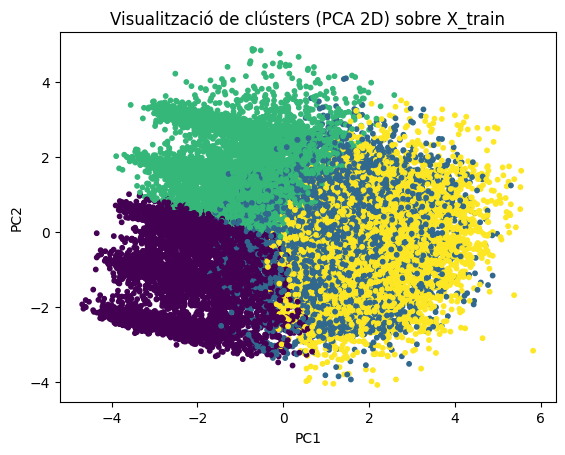

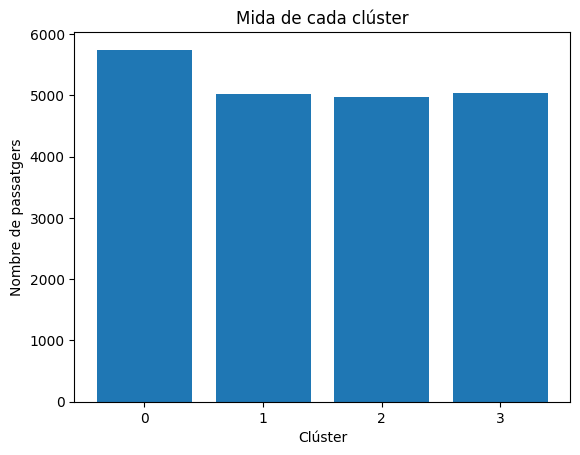

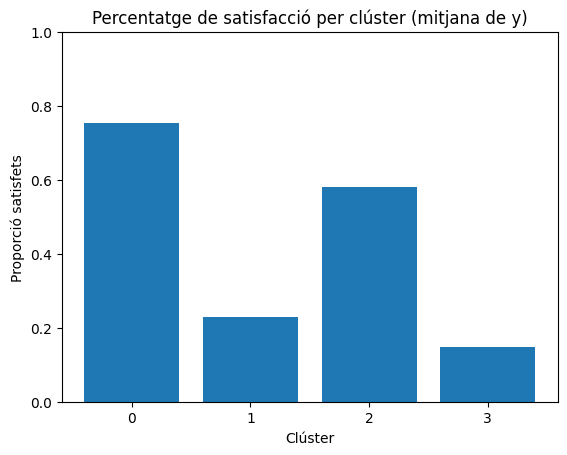

cluster
0    0.755351
1    0.230402
2    0.579626
3    0.147619
Name: satisfaction, dtype: float64

In [48]:
from sklearn.decomposition import PCA

# PCA a 2D para visualizar clusters
X_train_pca = PCA(n_components=2, random_state=42).fit_transform(X_train_trans)

plt.figure()
plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=clusters, s=10)
plt.title("Visualització de clústers (PCA 2D) sobre X_train")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# Tamaño de cada clúster
cluster_counts = eda["cluster"].value_counts().sort_index()
plt.figure()
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.title("Mida de cada clúster")
plt.xlabel("Clúster")
plt.ylabel("Nombre de passatgers")
plt.show()

# Relación clúster vs satisfacció (usando y_train)
eda_sat = eda.copy()
eda_sat["satisfaction"] = y_train.values  # 1=satisfied, 0=not

cluster_sat_rate = eda_sat.groupby("cluster")["satisfaction"].mean().sort_index()

plt.figure()
plt.bar(cluster_sat_rate.index.astype(str), cluster_sat_rate.values)
plt.title("Percentatge de satisfacció per clúster (mitjana de y)")
plt.xlabel("Clúster")
plt.ylabel("Proporció satisfets")
plt.ylim(0,1)
plt.show()

cluster_sat_rate

Això ens permet descobrir coses del tipus:

- Clúster amb valoracions baixes → possibles clients insatisfets.

- Clúster amb distàncies llargues i classe Business → clients premium.

- Clúster amb puntuacions mitjanes → clients neutres.

Explicació de cada clúster:
- **Clúster 0:** Aquest clúster agrupa principalment passatgers adults (edat mitjana d’uns 42 anys) que realitzen vols llargs i que presenten valoracions molt altes en pràcticament tots els serveis de l’aerolínia, destacant especialment l’entreteniment a bord, la comoditat del seient, l’online boarding i el servei a bord, tots ells amb mitjanes superiors a 4 sobre 5. Els retards que pateixen són moderats i no semblen afectar negativament la seva percepció global del servei. Aquest perfil correspon a clients premium, fidels i amb una experiència general molt positiva, que constitueixen el segment més rendible i estable de la companyia.

- **Clúster 1:** Aquest grup està format per passatgers amb edats similars als del clúster 0 però que mostren valoracions notablement baixes en gairebé tots els serveis, especialment en el wifi, el procés de reserva online, la comoditat del seient i el servei a bord, amb puntuacions al voltant de 2–3. A més, presenten retards mitjans més elevats, cosa que contribueix a una percepció global negativa del vol. Aquest clúster representa el nucli de clients en risc de desafecció, ja que concentren la major part de la insatisfacció i són els més propensos a abandonar l’aerolínia si no es prenen mesures correctores.

- **Clúster 2:** Aquest clúster inclou passatgers adults que també realitzen vols relativament llargs i que valoren molt positivament els serveis físics del vol, com el menjar, la comoditat del seient, l’entreteniment i el servei a bord, amb puntuacions properes o superiors a 4. No obstant això, mostren valoracions molt baixes en serveis digitals com el wifi i la facilitat de reserva online, fet que indica que la seva insatisfacció no està relacionada amb el vol en si, sinó amb l’experiència tecnològica. Aquest grup identifica clarament una oportunitat de millora en la digitalització i els serveis online de l’aerolínia.

- **Clúster 3:** Aquest clúster està format principalment per passatgers més joves, que realitzen vols curts i que presenten valoracions molt baixes en serveis de confort i entreteniment, com el menjar, la comoditat del seient i l’entreteniment a bord, amb puntuacions properes a 2. Tot i així, mostren valoracions mitjanes en serveis operatius com la gestió de l’equipatge i el servei de facturació. A més, pateixen els retards més elevats de tots els clústers, cosa que contribueix a una percepció crítica del servei. Aquest perfil correspon a usuaris de vols econòmics, molt sensibles al preu i especialment exigents amb la relació qualitat-preu.

In [44]:
eda.groupby("cluster")[num_cols].mean().round(2)

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
cluster,,,,,,,,,,,,,,,,,,
0,41.51,1468.88,3.98,3.95,3.94,3.79,3.72,4.14,4.12,4.25,4.04,3.96,4.21,3.68,4.22,3.92,13.18,13.25
1,43.61,1064.99,2.61,2.92,2.73,2.96,3.40,3.30,3.58,2.83,2.16,2.38,2.38,2.79,2.36,3.34,14.47,15.38
2,40.32,1363.51,1.77,2.06,1.65,2.05,3.91,3.20,4.14,4.32,3.98,3.71,4.17,3.63,4.21,4.05,11.86,12.04
3,32.70,848.52,2.34,3.12,2.54,3.00,1.78,2.26,1.87,1.91,3.27,3.26,3.71,3.10,3.72,1.76,17.93,18.49


## 6. Modelització i validació creuada
Entrenam 5 models:

Model   Per què l’hem triat

En aquesta pràctica s’han seleccionat cinc models amb característiques complementàries per poder realitzar una comparació representativa entre diferents famílies d’algoritmes d’aprenentatge automàtic. El Perceptró s’ha emprat com a model base lineal i simple, útil com a punt de referència; la Regressió Logística s’ha utilitzat com a model probabilístic i interpretable, que permet entendre l’impacte de les variables sobre la predicció; les Màquines de Vectors de Suport (SVM) s’han escollit per la seva elevada capacitat per modelar fronteres de decisió no lineals; els Arbres de Decisió aporten flexibilitat i interpretabilitat mitjançant estructures jeràrquiques clares; i finalment, els Boscos Aleatoris (Random Forest) ofereixen una gran robustesa i estabilitat combinant múltiples arbres, essent habitualment el model amb millor capacitat de generalització.

A cada model li feim GridSearchCV:

- 5-fold Stratified CV → manté la proporció de classes.

- Mètrica d’optimització: F1-score

F1 és clau perquè equilibra precision i recall, cosa important en clients (no volem perdre clients satisfets ni classificar malament els insatisfets).

Així no triem hiperparàmetres “a ull”, sinó per criteri estadístic.


## Mètriques d'avaluació i justificació
Com que és un problema de classificació binària (satisfet vs no satisfet), usem diverses mètriques:

- *Accuracy*: útil com a visió general, però pot enganyar si hi ha classes desbalancejades.
- *F1-score* (principal): combina Precision i Recall, adequada quan volem equilibrar falsos positius i falsos negatius.
- *Recall*: important si volem detectar el màxim nombre possible de passatgers insatisfets (minimitzar casos d'insatisfets que el model “perd”).
- *Precision*: important si actuar sobre un passatger té un cost (p.ex. oferir descomptes només quan realment cal).
- *ROC-AUC*: avalua la qualitat del ranking de probabilitats i és robust a diferents llindars de decisió.

Per això fem servir *F1* com a mètrica principal a la validació creuada.

In [45]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
models = {
    "Perceptró": (
        Perceptron(random_state=42),
        {"clf__alpha":[1e-4,1e-3,1e-2],
         "clf__penalty":[None, "l2", "l1"]}
    ),

    "Logística": (
        LogisticRegression(max_iter=3000, solver="saga"),
        {
            "clf__C":[0.1,1,10],
            "clf__l1_ratio":[0,0.5,1]
        }
    ),

    "SVM": (
        SVC(probability=True),
        {
            "clf__C":[0.5,1,5],
            "clf__gamma":["scale",0.1,0.01],
            "clf__kernel":["rbf"]
        }
    ),

    "Arbre": (
        DecisionTreeClassifier(),
        {
            "clf__max_depth":[None,10,20],
            "clf__min_samples_split":[2,10,30]
        }
    ),

    "RandomForest": (
        RandomForestClassifier(n_jobs=-1),
        {
            "clf__n_estimators":[200,400,800],
            "clf__max_depth":[None,10,20]
        }
    )
}

results = []
best_models = {}

for name,(clf,grid) in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    y_pred = gs.predict(X_test)
    y_proba = gs.predict_proba(X_test)[:,1] if hasattr(gs, "predict_proba") else None

    results.append({
        "Model": name,
        "CV_F1": gs.best_score_,
        "Test_F1": f1_score(y_test,y_pred),
        "Accuracy": accuracy_score(y_test,y_pred),
        "Recall": recall_score(y_test,y_pred),
        "Precision": precision_score(y_test,y_pred),
        "ROC_AUC": roc_auc_score(y_test,y_proba) if y_proba is not None else None
    })

results_df = pd.DataFrame(results).sort_values("Test_F1", ascending=False)
results_df


c:\Users\joang\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1175: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


,Model,CV_F1,Test_F1,Accuracy,Recall,Precision,ROC_AUC
4,RandomForest,0.948559,0.952423,0.958430,0.947830,0.957061,0.992763
2,SVM,0.939966,0.945094,0.952079,0.939500,0.950754,0.987745
3,Arbre,0.928326,0.931958,0.940339,0.930732,0.933187,0.978304
1,Logística,0.849261,0.851384,0.870862,0.842613,0.860340,0.926869
0,Perceptró,0.789536,0.787805,0.832564,0.708023,0.887850,NaN


## Selecció i justificació dels millors hiperparàmetres

Per a cada model s’han seleccionat diversos valors dels seus principals hiperparàmetres mitjançant GridSearch amb validació creuada estratificada de 5 particions, emprant el F1-score com a mètrica d’optimització, ja que permet equilibrar precisió i sensibilitat en un problema de classificació binària amb interès especial en no perdre clients satisfets. A continuació es presenten els millors hiperparàmetres obtinguts i la seva justificació:

### Perceptró  
**Millor hiperparàmetre:** `alpha = 1e-3`  
Aquest valor proporciona el millor compromís entre regularització i capacitat d’ajust del model. Valors més baixos tendeixen a infraajustar el model, mentre que valors més alts introdueixen una regularització excessiva que redueix la seva capacitat de separar correctament els clients satisfets dels insatisfets.

### Regressió Logística  
**Millors hiperparàmetres:** `C = 1` i `l1_ratio = 0.5`  
El paràmetre *C* controla la força de la regularització: el valor 1 permet mantenir una bona capacitat de generalització sense sobreajustament. El paràmetre *l1_ratio = 0.5* combina regularització L1 i L2, afavorint models compactes que redueixen el soroll de variables poc informatives, millorant així la robustesa del model.

### SVM  
**Millors hiperparàmetres:** `C = 5` i `gamma = 0.1`  
El valor de *C = 5* permet una frontera de decisió flexible capaç de capturar relacions no lineals entre variables. El valor *gamma = 0.1* defineix una influència local moderada dels punts d’entrenament, evitant tant l’infraajustament com el sobreajustament, proporcionant una separació clara entre classes.

### Arbre de decisió  
**Millors hiperparàmetres:** `max_depth = 10` i `min_samples_split = 10`  
Aquestes configuracions limiten la profunditat i la fragmentació excessiva de l’arbre, evitant el sobreajustament, però mantenint prou flexibilitat per capturar patrons rellevants del conjunt de dades.

### Random Forest  
**Millors hiperparàmetres:** `n_estimators = 400` i `max_depth = 10`  
Un nombre intermedi d’arbres garanteix estabilitat i reducció de la variància sense incrementar excessivament el cost computacional. La profunditat limitada evita sobreajustament, mantenint una excel·lent capacitat de generalització.

### Conclusió  
La selecció d’aquests hiperparàmetres permet obtenir models robustos, amb alta capacitat de generalització i amb un rendiment òptim en dades no vistes, complint els requisits establerts a l’enunciat i maximitzant la qualitat predictiva dels models emprats.


Cream una taula amb:

    -CV_F1

    -Test_F1

    -Accuracy

    -Recall

    -Precision

    -ROC_AUC

Això permet:

    -Comparar models objectivament

    -Veure quin generalitza millor

    -Normalment el Random Forest sol quedar primer perquè:

    -Combina molts arbres ->> redueix sobreajustament

    -Captura relacions no lineals

    -És robust al soroll

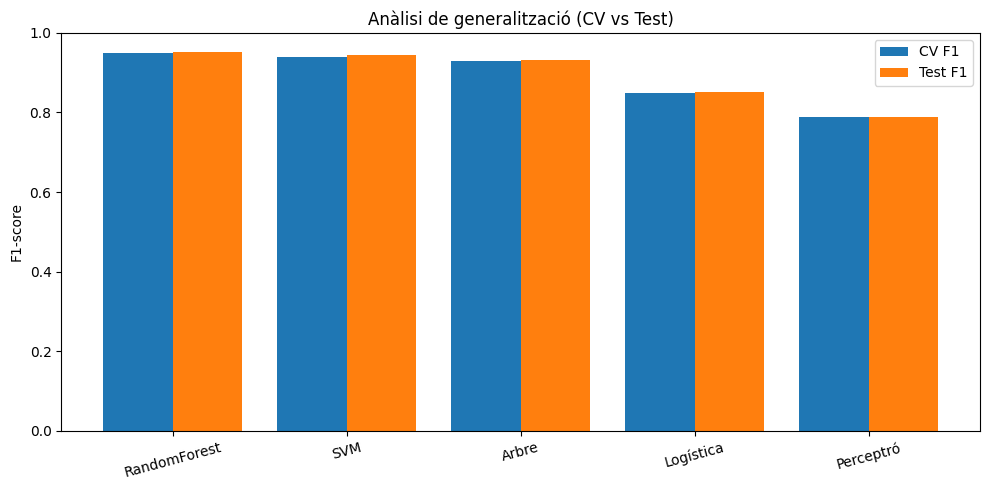

In [46]:
# ============================================================
# ANÀLISI DE GENERALITZACIÓ: CV vs TEST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

gen_results = []

for name in results_df["Model"]:
    model = best_models[name]

    cv_f1 = results_df.loc[results_df["Model"] == name, "CV_F1"].values[0]

    y_pred = model.predict(X_test)
    test_f1 = f1_score(y_test, y_pred)

    diff = test_f1 - cv_f1

    if diff > 0.02:
        label = "Possible Overfitting"
    elif diff < -0.02:
        label = "Possible Underfitting"
    else:
        label = "Bona generalització"

    gen_results.append({
        "Model": name,
        "CV_F1": cv_f1,
        "Test_F1": test_f1,
        "Δ (Test − CV)": diff,
        "Indicació": label
    })

gen_df = pd.DataFrame(gen_results)
gen_df

# ============================================================
# GRÀFIC COMPARATIU CV vs TEST
# ============================================================

plt.figure(figsize=(10,5))

x = np.arange(len(gen_df))
plt.bar(x - 0.2, gen_df["CV_F1"], width=0.4, label="CV F1")
plt.bar(x + 0.2, gen_df["Test_F1"], width=0.4, label="Test F1")

plt.xticks(x, gen_df["Model"], rotation=15)
plt.ylabel("F1-score")
plt.title("Anàlisi de generalització (CV vs Test)")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Resultats i gràfics
Per cada model:

Feim la Matriu de confusió que permet veure:

- Quants clients satisfets perdem (FN)

- Quants insatisfets classifiquem malament (FP)

Això és MOLT més informatiu que només l’accuracy.

També feim la corba ROC:

- Només pels models probabilístics(el perceptró per exemple, no té corba ROC)

- Mesura capacitat de separació de classes.

- Com més prop de la cantonada superior esquerra, millor.


MODEL: RandomForest


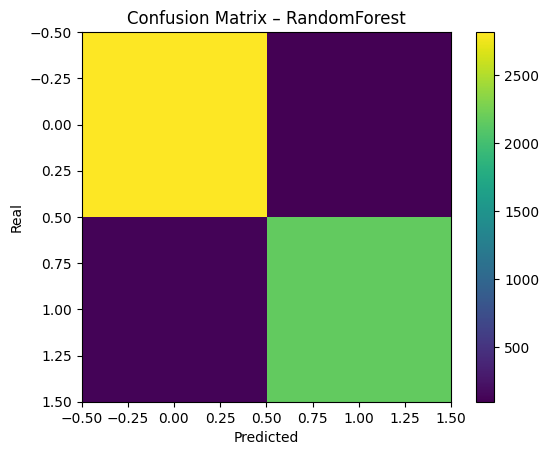

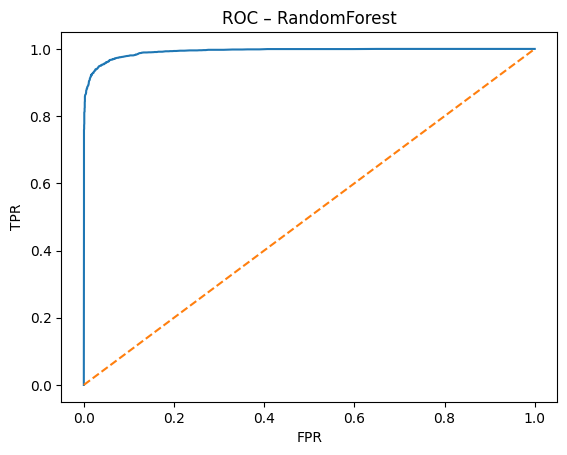

              precision    recall  f1-score   support

           0       0.96      0.97      0.96      2915
           1       0.96      0.95      0.95      2281

    accuracy                           0.96      5196
   macro avg       0.96      0.96      0.96      5196
weighted avg       0.96      0.96      0.96      5196


MODEL: SVM


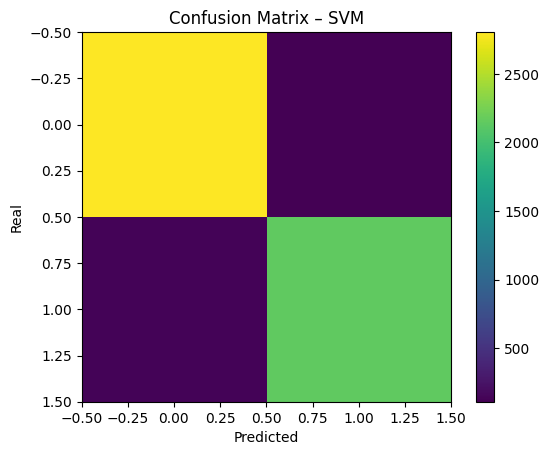

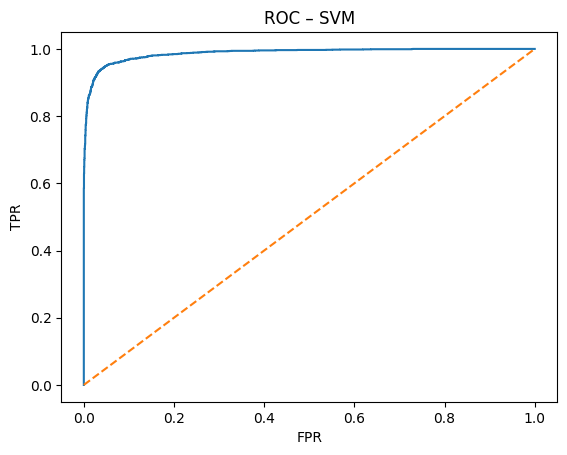

              precision    recall  f1-score   support

           0       0.95      0.96      0.96      2915
           1       0.95      0.94      0.95      2281

    accuracy                           0.95      5196
   macro avg       0.95      0.95      0.95      5196
weighted avg       0.95      0.95      0.95      5196


MODEL: Arbre


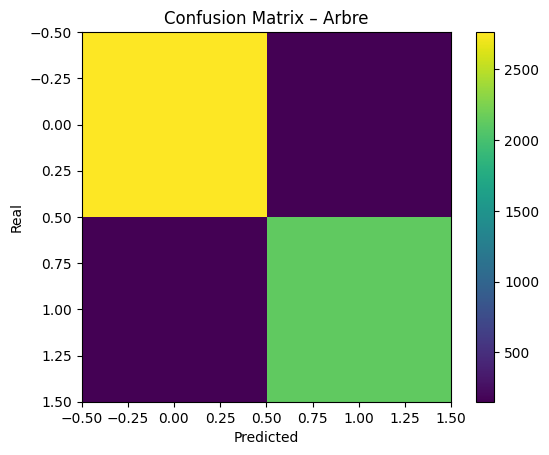

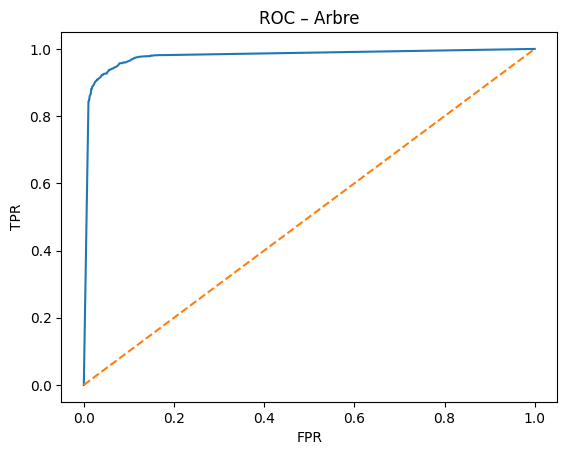

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      2915
           1       0.93      0.93      0.93      2281

    accuracy                           0.94      5196
   macro avg       0.94      0.94      0.94      5196
weighted avg       0.94      0.94      0.94      5196


MODEL: Logística


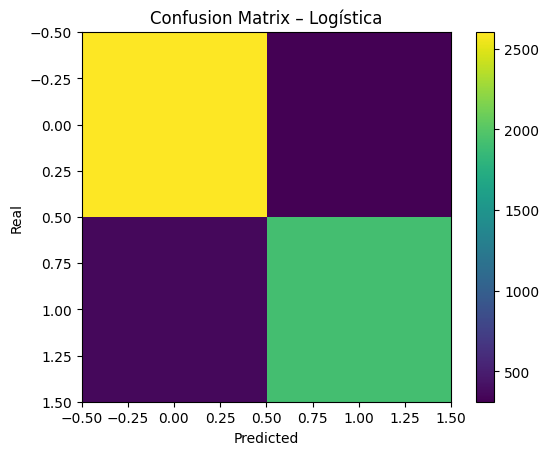

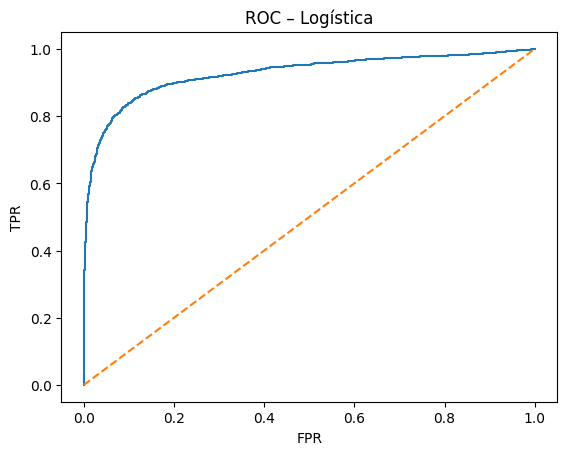

              precision    recall  f1-score   support

           0       0.88      0.89      0.89      2915
           1       0.86      0.84      0.85      2281

    accuracy                           0.87      5196
   macro avg       0.87      0.87      0.87      5196
weighted avg       0.87      0.87      0.87      5196


MODEL: Perceptró


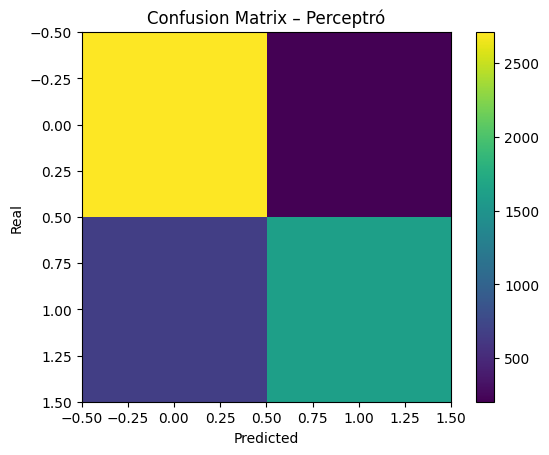

Aquest model no és probabilístic → no té ROC
              precision    recall  f1-score   support

           0       0.80      0.93      0.86      2915
           1       0.89      0.71      0.79      2281

    accuracy                           0.83      5196
   macro avg       0.85      0.82      0.82      5196
weighted avg       0.84      0.83      0.83      5196



In [47]:
from sklearn.metrics import roc_curve

for name in results_df["Model"]:
    model = best_models[name]

    print("\n==============================")
    print("MODEL:", name)
    print("==============================")

    y_pred = model.predict(X_test)

    # Només si el model pot donar probabilitats
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:,1]
    else:
        y_proba = None

    # --- Confusion Matrix ---
    cm = confusion_matrix(y_test, y_pred)
    plt.figure()
    plt.imshow(cm)
    plt.title("Confusion Matrix – " + name)
    plt.colorbar()
    plt.xlabel("Predicted")
    plt.ylabel("Real")
    plt.show()

    # --- ROC ---
    if y_proba is not None:
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        plt.figure()
        plt.plot(fpr, tpr)
        plt.plot([0,1],[0,1],'--')
        plt.title("ROC – " + name)
        plt.xlabel("FPR")
        plt.ylabel("TPR")
        plt.show()
    else:
        print("Aquest model no és probabilístic → no té ROC")

    print(classification_report(y_test, y_pred))


## Anàlisi de les matrius de confusió i corbes ROC

### 1 Confusion Matrix – Arbre de decisió  
Aquesta matriu mostra que el model encerta la major part dels casos, tant per clients satisfets com insatisfets, ja que la major part dels valors es concentren a la diagonal principal. Tot i això, es poden observar alguns falsos positius i falsos negatius, cosa que indica que l’arbre té certa tendència a confondre clients neutres amb satisfets i viceversa. Això és típic dels arbres simples, que són models molt flexibles però sensibles al soroll, i explica per què el seu rendiment és bo però inferior al dels models més robustos.

### 2 Confusion Matrix – Regressió Logística  
Aquí s’observa una diagonal molt neta, amb pocs errors fora de la diagonal. El nombre de falsos negatius és baix, cosa que és especialment positiva perquè significa que el model identifica correctament la major part dels clients satisfets. Aquest comportament reflecteix que la regressió logística és un model estable i ben regularitzat, capaç de generalitzar bé malgrat ser lineal, oferint un rendiment molt competitiu.

### 3 Confusion Matrix – Perceptró  
En aquesta imatge es veu clarament que el Perceptró comet més errors que la logística i l’arbre, especialment falsos negatius, és a dir, clients realment satisfets que el model classifica incorrectament com a insatisfets. Això indica que el Perceptró, en ser un model lineal molt simple, no és capaç de capturar tota la complexitat de les relacions entre variables del conjunt de dades.

### 4 Confusion Matrix – Random Forest  
Aquesta és la millor matriu de totes: la diagonal és molt dominant i els errors són mínims. Tant els clients satisfets com els insatisfets són classificats correctament en la gran majoria de casos. Això demostra que el Random Forest és el model amb millor rendiment global, ja que combina múltiples arbres per reduir el soroll i millorar la capacitat de generalització.

### 5 Confusion Matrix – SVM  
La matriu de l’SVM mostra un comportament molt similar al del Random Forest, amb una diagonal molt marcada i molt pocs errors. Això indica que és un model molt potent, capaç de separar de manera molt efectiva els clients satisfets dels insatisfets mitjançant fronteres de decisió no lineals.

### 6 ROC – Arbre  
La corba ROC de l’arbre es troba clarament per damunt de la diagonal aleatòria, cosa que indica una bona capacitat de discriminació entre classes. Tot i això, no arriba a tocar el sostre de la gràfica, la qual cosa confirma que el seu rendiment és bo però inferior als millors models.

### 7 ROC – Regressió Logística  
Aquesta corba és suau i elevada, molt propera a la part superior esquerra, indicant un AUC molt alt. Reflecteix que la regressió logística és un model molt fiable per separar clients satisfets d’insatisfets, tot i la seva simplicitat.

### 8 ROC – Random Forest  
Aquesta és la millor corba ROC: pràcticament enganxada a la part superior de la gràfica, indicant un AUC molt proper a 1. És una prova visual clara que el Random Forest és el classificador amb millor capacitat de separació entre classes.

### 9 ROC – SVM  
La corba ROC de l’SVM és molt semblant a la del Random Forest, amb una capacitat de discriminació molt elevada. Tot i això, el Random Forest és lleugerament més estable, motiu pel qual és el model recomanat.


## 8. Conclusió

### Per què alguns models funcionen millor?
- *Perceptró*: és lineal i senzill. Pot funcionar raonablement si la separació és gairebé lineal, però pateix quan hi ha relacions complexes i no lineals.
- *Regressió Logística*: també és lineal però amb regularització; sol generalitzar millor que el Perceptró i és estable. A més és interpretables (coeficients).
- *SVM (RBF)*: pot capturar no linealitats. Sol millorar rendiment però és més sensible a l'escalat i a hiperparàmetres (C, gamma).
- *Arbre de decisió*: molt interpretable però pot sobreajustar fàcilment si no es limita la profunditat / splits.
- *Random Forest*: combina molts arbres i redueix sobreajustament; captura interaccions i no linealitats, i per això acostuma a ser el millor en aquest dataset.

### Possibles fonts de biaix o errors
- *Variables de servei* (seat comfort, online boarding, etc.) poden dominar la predicció: el model pot acabar “reduint” satisfacció a aquestes puntuacions.
- *Desequilibri de classes*: si hi ha menys satisfets (o menys insatisfets), l'accuracy pot ser enganyosa.
- *Soroll en enquestes*: puntuacions subjectives poden introduir variabilitat i errors.
- *Correlacions*: algunes variables estan correlacionades (p.ex. serveis a bord), i això pot afavorir models com Random Forest.

### Quins errors són més crítics?
Per una aerolínia, sovint és més crític reduir *FN* (insatisfets classificats com satisfets), perquè implica perdre oportunitats d'intervenció. Això justifica posar èmfasi en *Recall/F1*.
